# Chapter 4 — ViFi-HMM: implementation and experiments

This notebook implements Chapter 4 of *Variance-Aware Regime Detection and Adaptive Forecasting*: the ViFi-HMM
model (Section 4.5, Eqs. 4.2–4.13, Algorithm 1) and the experiments of Section 4.6. It produces:

* **Synthetic data (Section 4.6.3.1):** Table 4.2 (ViFi-HMM ARI and purity, DTW-HAC ARI), the parameter recovery
  error, and Figures 4.2–4.4.
* **Stock indices (Section 4.6.3.2):** the ViFi-HMM Silhouette of Table 4.3, Figures 4.5–4.7 (alignment,
  precision–recall, ROC), Figure 4.10, and the temporal hold-out of Figure 4.8.
* **Currency pairs (Section 4.6.4):** the ViFi-HMM Silhouette of Table 4.3, Figure 4.9 and the volatility level of
  each FX cluster.
* **Ablation (Section 4.6.6):** Table 4.5, the full model against hard assignment (m = 1).
* **Downstream risk (Section 4.6.5):** the VaR breach rate of Table 4.4.

**Implementation settings** (each is a named setting in `CFG`):

| Choice | Setting | Default |
|---|---|---|
| Input scale for the HMMs | `STOCK_SCALING`, `FX_SCALING` | stocks: z-score each index on its own training statistics (Section 4.6.1.2). FX: one pooled training-period scale for all pairs (`"common"`), so the volatility level that separates the low / medium / high clusters is kept |
| Bad-tick cleaning | `CLEAN_SPIKES` | a day is a bad tick when it is an isolated spike: its log-return exceeds 10 robust scales (and 3 %), the next day reverses at least 60 % of it (or the move exceeds 25 % outright), and none of the five days either side, excluding the reversal day, moves more than 25 % of the spike. Crash days such as March 2020 sit inside turbulent spells, so they are kept. The price is replaced by the geometric mean of its neighbours. Every case is listed in Section 2.3 |
| Trading calendar | `STOCK_CALENDAR` | `"union_ffill"`: every day any index traded, with closed markets forward-filled |
| FCM initialisation features | `FCM_FEATURES` | mean and max of 20-day realised volatility and mean of 20-day rolling variance, from un-standardised returns, training period only |
| Emission initialisation | `INIT_ON_ABS` | k-means++ on \|returns\| of each cluster's main members, so the two states separate calm from turbulent days |
| State identity across clusters | always | states sorted by variance after every M-step, so state 1 is "calm" in every cluster (needed for the consensus in Eq. 4.6) |
| Membership step size | `PGD_ETA`, `PGD_STEPS` | normalised gradient steps: the membership vector moves at most `PGD_ETA` per step along the gradient direction |
| Fit term scale | `FIT_SCALE` | `"deficit"`: each series' ELBOs are centred on its best-fitting cluster (ELBO_ij − max_l ELBO_il ≤ 0), a per-series constant shift that leaves cluster rankings unchanged and gives the fit term the distance-like form of fuzzy c-means |
| Coherence term scale | `KL_SCALE` | `"per_obs"`: S_KL is averaged over time (divided by T_i), so λ has the same meaning whatever the series length |
| Validation split for early stopping | `VAL_FRAC` | last 20 % of each series (in time). The stopping and restart-selection criterion is the held-out log-likelihood of each series under its membership mix minus the coherence term at the target λ. No stop before 2R rounds |
| Hold-out | fixed | train ≤ 2011-12-31, test > 2011, as in Figure 4.8 |
| High-volatility labels for PR/ROC | `LABEL_QUANTILE` | day is "high-vol" when its 20-day realised volatility is above the series' 80th percentile |
| Stock universe | `STOCK_UNIVERSE` | `"ten"` (default): S&P 500, NASDAQ, Dow Jones, FTSE 100, DAX, CAC 40, Nikkei 225, Hang Seng, S&P/TSX Composite, ASX 200. Clustering runs on the panel; the per-index diagnostics (Figures 4.5–4.8, 4.10) are shown for the S&P 500 and FTSE 100 |
| FX universe | `FX_TICKERS` | fifteen USD pairs |
| Downstream evaluation (Table 4.4) | Section 12 | out-of-sample on 2012–2024 with the model trained to 2011; one-step-ahead volatility from causal posteriors; VaR breach rate averaged over five sub-periods |

**Offline mode.** If `yfinance` cannot download data, the notebook switches to simulated stand-in
series with the same shapes, prints a banner, and runs everything, so the pipeline can be checked
anywhere. Results from offline mode are not the thesis results.

In [1]:
import os, sys, time, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, silhouette_samples
warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True, precision=4, linewidth=160)

def show(df):
    try: display(df)
    except NameError: print(df)

CFG = dict(
    # ---- model (Section 4.5.6) ----
    C_STOCKS=2, C_FX=3, C_SYN=2, K=2,
    M=1.8, BETA=0.5, LAM_MAX=0.7, ANNEAL_R=5,
    PATIENCE=10, MAX_ROUNDS=150, RESTARTS=5, SEEDS=[0, 1, 2, 3, 4],
    PGD_ETA=0.1, PGD_STEPS=5, EPS_KL=1e-6, SD_FLOOR=1e-3, FIT_SCALE="deficit", KL_SCALE="per_obs",
    # ---- data ----
    STANDARDISE=True, INIT_ON_ABS=True, VAL_FRAC=0.20,
    STOCK_SCALING="per_series",   # z-score each index on its own training statistics (Section 4.6.1.2)
    FX_SCALING="common",          # one pooled training-period scale for all pairs, so volatility LEVEL survives (low / medium / high)
    CLEAN_SPIKES=True, SPIKE_K=10, SPIKE_FLOOR=0.03, SPIKE_REVERSAL=0.6, SPIKE_HARD_CAP=0.25,
    SPIKE_QUIET_WINDOW=5, SPIKE_QUIET_RATIO=0.25,   # a spike is a bad tick only if the 5 days either side (excluding the reversal day) all move < 25 % of it
    STOCK_CALENDAR="union_ffill",   # all days any market traded, closed markets forward-filled
    RV_WINDOW=20, LABEL_QUANTILE=0.80, HOLDOUT_SPLIT="2011-12-31",
    STOCK_START="2000-01-01", STOCK_END="2024-12-31",
    FX_START="2015-01-01", FX_END="2024-12-31",
    # "ten" = the ten-index panel used for clustering (Table 4.3 stocks, Table 4.5, Table 4.4);
    # "chapter" = only the S&P 500 and FTSE 100 (per-index diagnostics only).
    STOCK_UNIVERSE="ten",
    STOCK_TICKERS_CHAPTER={"^GSPC": "S&P 500", "^FTSE": "FTSE 100"},
    STOCK_TICKERS_TEN={"^GSPC": "S&P 500", "^IXIC": "NASDAQ", "^DJI": "Dow Jones", "^FTSE": "FTSE 100",
                       "^GDAXI": "DAX", "^FCHI": "CAC 40", "^N225": "Nikkei 225", "^HSI": "Hang Seng",
                       "^GSPTSE": "S&P/TSX Composite", "^AXJO": "ASX 200"},
    # fifteen USD pairs
    FX_TICKERS={"EURUSD=X": "USD/EUR", "GBPUSD=X": "USD/GBP", "JPY=X": "USD/JPY", "CHF=X": "USD/CHF",
                "CAD=X": "USD/CAD", "AUDUSD=X": "USD/AUD", "NZDUSD=X": "USD/NZD", "SEK=X": "USD/SEK",
                "NOK=X": "USD/NOK", "MXN=X": "USD/MXN", "ZAR=X": "USD/ZAR", "BRL=X": "USD/BRL",
                "TRY=X": "USD/TRY", "INR=X": "USD/INR", "PLN=X": "USD/PLN"},
    # ---- synthetic (Section 4.6.1.1) ----
    SYN_N_PER=50, SYN_T=200,
    SYN_A=dict(mu=[0.0, 0.0], sigma=[0.5, 2.0], stay=[0.95, 0.90]),
    SYN_B=dict(mu=[0.0, 0.0], sigma=[1.0, 1.5], stay=[0.80, 0.85]),   # "distinct transition dynamics"
    # ---- run control ----
    OUT_DIR="outputs_ch4", QUICK=False,
)
QUICK = os.environ.get("CH4_QUICK", "0") == "1" or CFG["QUICK"]
if QUICK:   # short smoke-test configuration (not for thesis results)
    CFG.update(SEEDS=[0, 1], RESTARTS=2, MAX_ROUNDS=40)
os.makedirs(CFG["OUT_DIR"], exist_ok=True)
CFG["STOCK_TICKERS"] = CFG["STOCK_TICKERS_CHAPTER"] if CFG["STOCK_UNIVERSE"] == "chapter" else CFG["STOCK_TICKERS_TEN"]
K = CFG["K"]
print("Stock universe:", CFG["STOCK_UNIVERSE"], "->", list(CFG["STOCK_TICKERS"].values()))
print("QUICK mode:", QUICK)

Stock universe: ten -> ['S&P 500', 'NASDAQ', 'Dow Jones', 'FTSE 100', 'DAX', 'CAC 40', 'Nikkei 225', 'Hang Seng', 'S&P/TSX Composite', 'ASX 200']
QUICK mode: False


## 1. Data utilities

In [2]:
def log_returns(prices):
    """prices: DataFrame (dates x series). Returns DataFrame of daily log-returns (decimal)."""
    return np.log(prices / prices.shift(1)).iloc[1:]

def realised_vol(r, w=20):
    """Rolling realised volatility (annualised, %) of a 1-D return array; NaN for the first w-1 days."""
    s = pd.Series(r).rolling(w).std(ddof=1) * np.sqrt(252) * 100
    return s.values

def volatility_features(R, train_mask):
    """Per-series FCM features from un-standardised returns on the training period:
    mean 20-day realised vol, max 20-day realised vol, mean 20-day rolling variance (x1e4)."""
    feats = []
    for r in R:
        rt = r[train_mask] if train_mask is not None else r
        rv = realised_vol(rt, CFG["RV_WINDOW"])
        var = pd.Series(rt).rolling(CFG["RV_WINDOW"]).var(ddof=1).values * 1e4
        feats.append([np.nanmean(rv), np.nanmax(rv), np.nanmean(var)])
    return np.array(feats)

def standardise(R, train_mask):
    """z-score each series using its own training-period mean and sd."""
    mu = R[:, train_mask].mean(1, keepdims=True)
    sd = R[:, train_mask].std(1, ddof=1, keepdims=True)
    return (R - mu) / sd

def scale_panel(X_raw, train_mask, mode):
    """Scale a (N,T) panel of decimal log-returns. Returns (scaled, sd_units (N,1)) with sd_units converting back to decimals.
    'per_series': each series on its own training mean/sd. 'common': per-series mean, one pooled training sd for all series.
    'none': unchanged."""
    mu = X_raw[:, train_mask].mean(1, keepdims=True)
    if mode == "per_series": sd = X_raw[:, train_mask].std(1, ddof=1, keepdims=True)
    elif mode == "common":   sd = np.full((X_raw.shape[0], 1), X_raw[:, train_mask].std(ddof=1))
    else:                    return X_raw.copy(), np.ones((X_raw.shape[0], 1))
    return (X_raw - mu) / sd, sd

def clean_spikes(prices, k=10, floor=0.03, reversal=0.6, hard_cap=0.25, quiet_window=5, quiet_ratio=0.25, window=60):
    """Remove bad ticks, i.e. ISOLATED spikes. A day is a candidate when its log-return exceeds k robust scales (and
    `floor`) and the next day reverses at least `reversal` of it, or when it exceeds `hard_cap` outright. A candidate
    is removed only if it is isolated: the largest move in the `quiet_window` days either side, excluding the spike
    and the reversal day, is below `quiet_ratio` x the spike. Genuine crash days sit inside turbulent spells (large
    moves on the surrounding days), so they fail the isolation test and are kept. The removed price is replaced by
    the geometric mean of its neighbours. Returns (cleaned prices, report of every candidate, removed or kept)."""
    px = prices.copy(); report = {}
    for col in px.columns:
        p = px[col].values.astype(float)
        for _ in range(3):
            r = np.diff(np.log(p)); n = len(r)
            scale = pd.Series(np.abs(r)).rolling(window, min_periods=20).median().bfill().ffill().values * 1.4826
            bad = []
            for t in range(n - 1):
                big = abs(r[t]) > max(k * scale[t], floor)
                rev_share = -r[t + 1] / r[t] if r[t] != 0 else 0.0            # share of the move undone the next day
                if not (abs(r[t]) > hard_cap or (big and rev_share >= reversal)): continue
                around = np.r_[r[max(0, t - quiet_window):t], r[t + 2:min(n, t + 2 + quiet_window)]]
                iso = float(np.abs(around).max() / abs(r[t])) if len(around) else 0.0
                removed = iso < quiet_ratio
                key = (col, str(px.index[t + 1].date()))
                if key not in report:
                    report[key] = dict(series=col, date=key[1], move_pct=round(float(r[t]) * 100, 2),
                                       reversed_next_day_pct=round(100 * rev_share, 1), largest_nearby_vs_spike=round(iso, 2),
                                       action="removed (isolated spike)" if removed else "kept (inside a turbulent spell)")
                if removed: bad.append(t + 1)
            if not bad: break
            for i in bad:
                if 0 < i < len(p) - 1: p[i] = np.sqrt(p[i - 1] * p[i + 1])
        px[col] = p
    cols = ["series", "date", "move_pct", "reversed_next_day_pct", "largest_nearby_vs_spike", "action"]
    return px, pd.DataFrame(list(report.values()), columns=cols)

def apply_calendar(px, mode):
    """'union_ffill': every day any series traded, closed markets forward-filled. 'intersection': days all series traded."""
    px = px.dropna(how="all")
    return px.dropna(how="any") if mode == "intersection" else px.ffill().dropna()

def make_time_masks(n, val_frac):
    n_val = int(round(n * val_frac))
    train = np.zeros(n, bool); train[: n - n_val] = True
    return train, ~train

## 2. Datasets
### 2.1 Synthetic regime-controlled data (Section 4.6.1.1)

In [3]:
def simulate_hmm_series(rng, T, mu, sigma, stay):
    """Two-state Gaussian HMM sample. Returns (x, states)."""
    s = np.zeros(T, int); s[0] = rng.integers(2)
    for t in range(1, T):
        s[t] = s[t - 1] if rng.random() < stay[s[t - 1]] else 1 - s[t - 1]
    x = rng.normal(np.asarray(mu)[s], np.asarray(sigma)[s])
    return x, s

def make_synthetic(seed):
    rng = np.random.default_rng(seed)
    X, S, y = [], [], []
    for lab, spec in enumerate([CFG["SYN_A"], CFG["SYN_B"]]):
        for _ in range(CFG["SYN_N_PER"]):
            x, s = simulate_hmm_series(rng, CFG["SYN_T"], **spec)
            X.append(x); S.append(s); y.append(lab)
    return np.array(X), np.array(S), np.array(y)

### 2.2 Real data (Sections 4.6.1.2 and 4.6.1.3), with an offline stand-in

In [4]:
def download_prices(tickers, start, end):
    """Raw closes on the union of trading days; NaN where a market was closed (the calendar is applied later)."""
    import yfinance as yf
    px = yf.download(list(tickers), start=start, end=end, auto_adjust=True, progress=False)["Close"]
    px = px.rename(columns=tickers).dropna(how="all")
    return px[[tickers[t] for t in tickers if tickers[t] in px.columns]]

def simulate_panel(names, start, end, seed, vol_profiles, holiday_rates=None):
    """Offline stand-in: regime-switching series with the right shape, with NaN on simulated local holidays. NOT real data."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, end)
    T = len(dates)
    cols = {}
    for k_, (name, (cv, tv, cs, ts)) in enumerate(zip(names, vol_profiles)):
        r, _ = simulate_hmm_series(rng, T, [0, 0], [cv / 100, tv / 100], [1 - 1 / cs, 1 - 1 / ts])
        p = 100 * np.exp(np.cumsum(r))
        if holiday_rates is not None:
            p[1:][rng.random(T - 1) < holiday_rates[k_]] = np.nan
        cols[name] = p
    return pd.DataFrame(cols, index=dates)

def load_real_data():
    """Returns dict with raw price DataFrames for stocks and FX (NaN on closed days), and a flag saying whether they are real."""
    try:
        stocks = download_prices(CFG["STOCK_TICKERS"], CFG["STOCK_START"], CFG["STOCK_END"])
        fx = download_prices(CFG["FX_TICKERS"], CFG["FX_START"], CFG["FX_END"])
        assert stocks.shape[1] >= 2 and fx.shape[1] >= 2
        print(f"Downloaded {stocks.shape[1]} indices ({stocks.index[0].date()} to {stocks.index[-1].date()}) "
              f"and {fx.shape[1]} FX pairs ({fx.index[0].date()} to {fx.index[-1].date()}).")
        return dict(stocks_raw=stocks, fx_raw=fx, real=True)
    except Exception as e:
        print("=" * 90 + f"\nOFFLINE MODE: could not download market data ({type(e).__name__}: {e}).\n"
              "Using simulated stand-in series. Numbers below are NOT the thesis results.\n" + "=" * 90)
        s_end = CFG["STOCK_END"]
        if QUICK:
            s_start = "2019-01-01"
        else:
            s_start = CFG["STOCK_START"]
        stock_prof = [(0.7, 2.0, 120, 30), (1.1, 2.8, 120, 30), (0.7, 1.9, 120, 30), (0.7, 1.8, 120, 30),
                      (0.8, 2.1, 120, 30), (0.9, 2.2, 120, 30), (1.1, 2.4, 100, 30), (1.2, 2.6, 100, 30),
                      (0.9, 2.3, 110, 30), (0.7, 1.9, 120, 30)]
        fx_prof = [(0.40, 0.8, 120, 40), (0.45, 0.95, 120, 40), (0.45, 0.9, 120, 40), (0.45, 1.0, 120, 40),
                   (0.40, 0.8, 120, 40), (0.55, 1.1, 110, 35), (0.60, 1.2, 110, 35), (0.55, 1.1, 110, 35),
                   (0.60, 1.2, 110, 35), (0.65, 1.5, 100, 30), (0.80, 1.7, 100, 30), (0.80, 1.8, 100, 30),
                   (0.60, 3.0, 80, 20), (0.30, 0.9, 120, 40), (0.50, 1.1, 110, 35)]
        names = list(CFG["STOCK_TICKERS"].values())
        hol = [0.06 if n in ("Nikkei 225", "Hang Seng") else 0.035 for n in names]
        stocks = simulate_panel(names, s_start, s_end, 11, stock_prof[:len(names)], hol)
        fx = simulate_panel(list(CFG["FX_TICKERS"].values()), CFG["FX_START"] if not QUICK else "2020-01-01",
                            CFG["FX_END"], 12, fx_prof)
        return dict(stocks_raw=stocks, fx_raw=fx, real=False)

DATA = load_real_data()
DATA["stocks"] = apply_calendar(DATA["stocks_raw"], CFG["STOCK_CALENDAR"])
DATA["fx"] = apply_calendar(DATA["fx_raw"], "union_ffill")     # FX pairs trade on the same weekdays; the few gaps are forward-filled
print("Stock calendar:", CFG["STOCK_CALENDAR"], f"-> {len(DATA['stocks'])} days")
STOCK_NAMES = list(DATA["stocks"].columns); FX_NAMES = list(DATA["fx"].columns)

Downloaded 10 indices (2000-01-03 to 2024-12-30) and 15 FX pairs (2015-01-01 to 2024-12-30).
Stock calendar: union_ffill -> 6503 days


### 2.3 Data quality: bad-tick cleaning

Every large one-day reversal is listed with what was done to it. `largest_nearby_vs_spike` is the largest move in
the five days either side (excluding the reversal day) as a share of the spike: below 0.25 the spike is isolated
and removed as a bad tick, above it the move sits inside a turbulent spell and is kept.

In [5]:
def max_move_table(R): return (R.abs().max() * 100).round(2).rename("max |daily log-return| %")
spike_kw = dict(k=CFG["SPIKE_K"], floor=CFG["SPIKE_FLOOR"], reversal=CFG["SPIKE_REVERSAL"], hard_cap=CFG["SPIKE_HARD_CAP"],
                quiet_window=CFG["SPIKE_QUIET_WINDOW"], quiet_ratio=CFG["SPIKE_QUIET_RATIO"])
raw_max = pd.concat([max_move_table(log_returns(DATA["stocks"])), max_move_table(log_returns(DATA["fx"]))])
n_removed = 0
if CFG["CLEAN_SPIKES"]:
    DATA["stocks"], rep_s = clean_spikes(DATA["stocks"], **spike_kw)
    DATA["fx"], rep_f = clean_spikes(DATA["fx"], **spike_kw)
    spike_report = pd.concat([rep_s, rep_f], ignore_index=True)
    n_removed = int((spike_report.action.str.startswith("removed")).sum()) if len(spike_report) else 0
    print(f"Large one-day reversals found: {len(spike_report)} | removed as isolated bad ticks: {n_removed} | "
          f"kept as genuine market moves: {len(spike_report) - n_removed}")
    if len(spike_report): show(spike_report.sort_values(["action", "series", "date"]).reset_index(drop=True))
    spike_report.to_csv(f"{CFG['OUT_DIR']}/data_cleaning_report.csv", index=False)
R_STOCKS = log_returns(DATA["stocks"]); R_FX = log_returns(DATA["fx"])
qc = pd.concat([raw_max.rename("before cleaning"), pd.concat([max_move_table(R_STOCKS), max_move_table(R_FX)]).rename("after cleaning")], axis=1)
show(qc); qc.to_csv(f"{CFG['OUT_DIR']}/data_quality_max_moves.csv")
print("stocks:", R_STOCKS.shape, "| fx:", R_FX.shape)

Large one-day reversals found: 15 | removed as isolated bad ticks: 5 | kept as genuine market moves: 10


,series,date,move_pct,reversed_next_day_pct,largest_nearby_vs_spike,action
0,Dow Jones,2020-03-12,-10.52,85.1,1.32,kept (inside a turbulent spell)
1,Dow Jones,2020-03-13,8.95,154.7,1.18,kept (inside a turbulent spell)
2,Nikkei 225,2024-08-05,-13.23,73.6,0.45,kept (inside a turbulent spell)
3,S&P 500,2020-03-09,-7.90,61.0,1.62,kept (inside a turbulent spell)
4,S&P 500,2020-03-12,-9.99,88.9,1.28,kept (inside a turbulent spell)
5,S&P 500,2020-03-13,8.88,143.7,1.13,kept (inside a turbulent spell)
6,S&P/TSX Composite,2020-03-12,-13.18,70.0,0.82,kept (inside a turbulent spell)
7,S&P/TSX Composite,2020-03-13,9.22,112.9,1.43,kept (inside a turbulent spell)
8,USD/NOK,2020-03-23,41.89,5.8,0.79,kept (inside a turbulent spell)
9,USD/TRY,2021-11-24,11.68,62.7,0.52,kept (inside a turbulent spell)


,before cleaning,after cleaning
Ticker,,
S&P 500,12.77,12.77
NASDAQ,13.25,13.25
Dow Jones,13.84,13.84
FTSE 100,11.51,11.51
DAX,13.05,13.05
CAC 40,13.10,13.10
Nikkei 225,13.23,13.23
Hang Seng,13.58,13.58
S&P/TSX Composite,13.18,13.18


stocks: (6502, 10) | fx: (2606, 15)


## 3. HMM machinery: forward–backward and filtered posteriors

In [6]:
def gaussian_logpdf(X, mu, sd):
    """X (N,T) ; mu, sd (C,K) -> log densities (N,C,T,K)."""
    z = (X[:, None, :, None] - mu[None, :, None, :]) / sd[None, :, None, :]
    return -0.5 * z ** 2 - np.log(sd[None, :, None, :]) - 0.5 * np.log(2 * np.pi)

def forward_backward(X, pi, A, mu, sd):
    """Exact posteriors for every (series, cluster) pair (Algorithm 1, lines 4–9).
    Returns gamma (N,C,T,K), xi_sum (N,C,K,K), loglik (N,C) = ELBO_ij at the exact posterior."""
    N, T = X.shape; C = pi.shape[0]
    B = np.exp(gaussian_logpdf(X, mu, sd)); B = np.maximum(B, 1e-300)
    al = np.empty((N, C, T, K)); c = np.empty((N, C, T))
    a = pi[None] * B[:, :, 0]; c[:, :, 0] = a.sum(-1); al[:, :, 0] = a / c[:, :, 0, None]
    for t in range(1, T):
        a = np.einsum("nck,ckl->ncl", al[:, :, t - 1], A) * B[:, :, t]
        c[:, :, t] = a.sum(-1); al[:, :, t] = a / c[:, :, t, None]
    be = np.ones((N, C, T, K)); xi_sum = np.zeros((N, C, K, K))
    for t in range(T - 2, -1, -1):
        bb = B[:, :, t + 1] * be[:, :, t + 1]
        be[:, :, t] = np.einsum("ckl,ncl->nck", A, bb) / c[:, :, t + 1, None]
        xi = al[:, :, t, :, None] * A[None] * bb[:, :, None, :]
        xi_sum += xi / xi.sum((-1, -2), keepdims=True)
    g = al * be; g /= g.sum(-1, keepdims=True)
    return g, xi_sum, np.log(c).sum(-1)

def filtered_posteriors(X, pi, A, mu, sd):
    """Causal (forward-only) state probabilities (N,C,T,K): uses information up to day t only."""
    N, T = X.shape; C = pi.shape[0]
    B = np.maximum(np.exp(gaussian_logpdf(X, mu, sd)), 1e-300)
    al = np.empty((N, C, T, K))
    a = pi[None] * B[:, :, 0]; al[:, :, 0] = a / a.sum(-1, keepdims=True)
    for t in range(1, T):
        a = np.einsum("nck,ckl->ncl", al[:, :, t - 1], A) * B[:, :, t]
        al[:, :, t] = a / a.sum(-1, keepdims=True)
    return al

## 4. ViFi-HMM (Section 4.5, Algorithm 1)

In [7]:
def fcm(X, C, m, rng, iters=500, tol=1e-10):
    """Fuzzy c-means on rows of X. Returns memberships (N,C) and centres (C,d)."""
    cent = X[rng.choice(len(X), C, replace=False)].astype(float).copy()
    for _ in range(iters):
        d = np.linalg.norm(X[:, None, :] - cent[None], axis=2) + 1e-12
        U = 1 / ((d[:, :, None] / d[:, None, :]) ** (2 / (m - 1))).sum(2)
        new = (U ** m).T @ X / (U ** m).sum(0)[:, None]
        if np.abs(new - cent).max() < tol: cent = new; break
        cent = new
    d = np.linalg.norm(X[:, None, :] - cent[None], axis=2) + 1e-12
    return 1 / ((d[:, :, None] / d[:, None, :]) ** (2 / (m - 1))).sum(2), cent

def project_simplex(v, floor=1e-6):
    u = np.sort(v)[::-1]; css = np.cumsum(u)
    rho = np.nonzero(u * np.arange(1, len(v) + 1) > (css - 1))[0][-1]
    w = np.maximum(v - (css[rho] - 1) / (rho + 1), floor)
    return w / w.sum()

def coherence_series(u, gi, m, eps):
    """Eq. 4.6–4.8 for one series: weighted penalty, per-cluster D_KL^(j)(X_i), consensus (T,K)."""
    w = u ** m
    gbar = (w[:, None, None] * gi).sum(0) / w.sum()
    kl = np.where(gi > 0, gi * np.log(np.maximum(gi, 1e-300) / (gbar[None] + eps)), 0.0).sum((1, 2))
    return (w * kl).sum(), kl, gbar

class ViFiHMM:
    """Variational Fuzzy HMM clustering (Chapter 4)."""

    def __init__(self, C, K=2, m=1.8, beta=0.5, lam_max=0.7, anneal_R=5, patience=10, max_rounds=150,
                 restarts=5, pgd_eta=0.1, pgd_steps=5, eps=1e-6, sd_floor=1e-3, init_on_abs=True,
                 hard=False, fit_scale="deficit", kl_scale="per_obs", verbose=False):
        self.C, self.K, self.m, self.beta, self.lam_max, self.R = C, K, m, beta, lam_max, anneal_R
        self.fit_scale = fit_scale   # "raw" = Eq. 4.4 literally | "deficit" = ELBO centred per series on its best cluster | "per_obs_deficit" = deficit / T
        self.kl_scale = kl_scale     # "total" = Eq. 4.7 literally (sum over t) | "per_obs" = averaged over t (divided by T)
        self.patience, self.max_rounds, self.restarts = patience, max_rounds, restarts
        self.eta, self.steps, self.eps, self.sd_floor = pgd_eta, pgd_steps, eps, sd_floor
        self.init_on_abs, self.hard, self.verbose = init_on_abs, hard, verbose

    # ---- initialisation (Section 4.5.6) ----
    def _init(self, X, F, rng):
        C, K = self.C, self.K
        Fs = (F - F.mean(0)) / (F.std(0) + 1e-12)
        m0 = max(self.m, 1.5)                                                    # FCM needs m > 1 even when the model uses m = 1
        U, _ = fcm(Fs, C, m0, rng)
        order = np.argsort((U ** m0).T @ F[:, 0] / (U ** m0).sum(0))         # cluster 1 = calmest
        U = np.clip(U[:, order], 1e-6, None); U /= U.sum(1, keepdims=True)
        pi = np.full((C, K), 1.0 / K); A = np.zeros((C, K, K)); mu = np.zeros((C, K)); sd = np.zeros((C, K))
        for j in range(C):
            mem = np.where(U.argmax(1) == j)[0]
            if len(mem) == 0: mem = np.argsort(-U[:, j])[:1]
            x = X[mem].ravel()
            feat = np.abs(x) if self.init_on_abs else x
            lab = KMeans(K, init="k-means++", n_init=3, random_state=int(rng.integers(1 << 31))).fit_predict(feat[:, None])
            mus = np.array([x[lab == k].mean() for k in range(K)])
            sds = np.array([max(x[lab == k].std(), self.sd_floor) for k in range(K)])
            o = np.argsort(sds); mu[j], sd[j] = mus[o], sds[o]
            stay = rng.uniform(0.85, 0.95, K)                                    # mild self-transition bias
            A[j] = np.eye(K) * stay[:, None] + (1 - stay)[:, None] * (1 - np.eye(K)) / (K - 1)
        return U, (pi, A, mu, sd)

    # ---- objective pieces (Eq. 4.9) ----
    def _scaled(self, E, T):
        """Fit scores used in the objective, and the matching scale for S_KL."""
        kls = 1.0 if self.kl_scale == "total" else 1.0 / T
        if self.fit_scale == "raw": return E, kls
        D = E - E.max(1, keepdims=True)                       # <= 0 ; 0 for the best-fitting cluster
        return (D, kls) if self.fit_scale == "deficit" else (D / T, kls)

    def _objective(self, U, E, G, lam, kls=1.0, include_entropy=True):
        fit = (U ** self.m * E).sum()
        ent = -(U * np.log(np.maximum(U, 1e-12))).sum()
        S = kls * sum(coherence_series(U[i], G[i], self.m, self.eps)[0] for i in range(len(U)))
        return fit + (self.beta * ent if include_entropy else 0.0) - lam * S, fit, ent, S

    def _holdout_score(self, U, E, G, kls):
        W = U ** self.m; W = W / W.sum(1, keepdims=True)
        S = kls * sum(coherence_series(U[i], G[i], self.m, self.eps)[0] for i in range(len(U)))
        return float((W * E).sum() - self.lam_max * S)

    def _grad(self, u, e, gi, lam, kls=1.0):
        """Eq. 4.10–4.11; dS_KL/du by central finite differences through Eq. 4.6."""
        C = self.C
        g = self.m * u ** (self.m - 1) * e + self.beta * (-(1 + np.log(np.maximum(u, 1e-12))))
        if lam > 0:
            gk = np.zeros(C)
            for j in range(C):
                h = 1e-6 * max(u[j], 1e-3); up = u.copy(); dn = u.copy()
                up[j] += h; dn[j] = max(dn[j] - h, 1e-12)
                gk[j] = (coherence_series(up, gi, self.m, self.eps)[0] - coherence_series(dn, gi, self.m, self.eps)[0]) / (up[j] - dn[j])
            g = g - lam * kls * gk
        return g

    def _update_U(self, U, E, G, lam, kls=1.0):
        U = U.copy()
        for i in range(len(U)):
            u = U[i]
            if self.hard:   # m = 1, hard assignment: exact maximiser of the membership-linear objective (hard EM)
                score = E[i] - lam * kls * coherence_series(u, G[i], self.m, self.eps)[1]
                h = np.full(self.C, 1e-6); h[score.argmax()] = 1.0; U[i] = h / h.sum(); continue
            for _ in range(self.steps):
                g = self._grad(u, E[i], G[i], lam, kls)
                u = project_simplex(u + self.eta * g / (np.abs(g).max() + 1e-12))   # normalised PGD step
            U[i] = u
        if self.hard:   # empty-cluster safeguard (as in k-means / hard EM): re-seed with the most ambiguous series
            lab = U.argmax(1)
            for j in range(self.C):
                if (lab == j).sum() == 0:
                    srt = np.sort(E, 1); margin = srt[:, -1] - srt[:, -2]
                    cand = np.argsort(margin)
                    for i in cand:
                        if (lab == lab[i]).sum() > 1:
                            h = np.full(self.C, 1e-6); h[j] = 1.0; U[i] = h / h.sum(); lab[i] = j; break
        return U

    # ---- fuzzy-weighted Baum–Welch (Eq. 4.12–4.13) ----
    def _m_step(self, X, U, G, XI):
        C, K = self.C, self.K
        pi = np.zeros((C, K)); A = np.zeros((C, K, K)); mu = np.zeros((C, K)); sd = np.zeros((C, K))
        for j in range(C):
            w = U[:, j] ** self.m
            pi[j] = (w[:, None] * G[:, j, 0]).sum(0) / w.sum()
            num = (w[:, None, None] * XI[:, j]).sum(0)
            A[j] = num / num.sum(1, keepdims=True)
            occ = (w[:, None] * G[:, j].sum(1)).sum(0)
            mu[j] = (w[:, None] * (G[:, j] * X[:, :, None]).sum(1)).sum(0) / occ
            var = (w[:, None] * (G[:, j] * (X[:, :, None] - mu[j]) ** 2).sum(1)).sum(0) / occ
            sd[j] = np.sqrt(np.maximum(var, self.sd_floor ** 2))
            o = np.argsort(sd[j])                       # state identity: 0 = calm, 1 = turbulent
            pi[j], A[j], mu[j], sd[j] = pi[j][o], A[j][np.ix_(o, o)], mu[j][o], sd[j][o]
        return pi, A, mu, sd

    def _fit_once(self, X, F, train_mask, seed):
        rng = np.random.default_rng(seed)
        Xtr, Xva = X[:, train_mask], X[:, ~train_mask]
        U, theta = self._init(Xtr, F, rng); U_init = U.copy()
        best = None; since = 0; hist = []
        for t in range(1, self.max_rounds + 1):
            lam = self.lam_max * (1 - np.exp(-t / self.R))
            G, XI, E = forward_backward(Xtr, *theta)                               # posterior step
            Es, kls = self._scaled(E, Xtr.shape[1])
            J_tr = self._objective(U, Es, G, lam, kls)
            # validation criterion: held-out log-likelihood of each series under its membership mix (normalised fuzzy
            # weights, uncentred ELBOs), minus the coherence term at the target lambda. The membership-entropy term
            # depends only on training memberships and is left out; centred ELBOs are not used here because they
            # are maximised by identical clusters, which would favour collapsed models.
            if Xva.shape[1] > 0:
                Gv, _, Ev = forward_backward(Xva, *theta); klv = self._scaled(Ev, Xva.shape[1])[1]
                J_va = self._holdout_score(U, Ev, Gv, klv)
            else:
                J_va = self._holdout_score(U, E, G, kls)
            hist.append(dict(round=t, lam=lam, J_train=J_tr[0], fit=J_tr[1], entropy=J_tr[2], S_KL=J_tr[3], J_val=J_va))
            if best is None or J_va > best["J_val"] + 1e-9:
                best = dict(J_val=J_va, U=U.copy(), theta=theta, round=t); since = 0
            else:
                since += 1
                if since >= self.patience and t >= 2 * self.R: break
            U = self._update_U(U, Es, G, lam, kls)                                 # membership update
            theta = self._m_step(Xtr, U, G, XI)                                    # model update
        best["history"] = pd.DataFrame(hist); best["U0"] = U_init
        return best

    def fit(self, X, F=None, train_mask=None, seed=0):
        """X (N,T) standardised returns; F (N,d) FCM features; train_mask (T,) bool."""
        N, T = X.shape
        if train_mask is None: train_mask = np.ones(T, bool)
        if F is None: F = volatility_features(X, train_mask)
        runs = [self._fit_once(X, F, train_mask, seed * 1000 + r) for r in range(self.restarts)]
        b = max(runs, key=lambda r: r["J_val"])
        self.U_, (self.pi_, self.A_, self.mu_, self.sd_) = b["U"], b["theta"]
        self.history_, self.best_round_, self.restart_scores_ = b["history"], b["round"], [r["J_val"] for r in runs]
        self.U0_ = b["U0"]                                                          # FCM initial memberships of the selected restart
        self.train_mask_ = train_mask
        return self

    # ---- inference helpers ----
    def posteriors(self, X):
        """Smoothed state posteriors (N,C,T,K) and ELBO_ij (N,C)."""
        G, _, E = forward_backward(X, self.pi_, self.A_, self.mu_, self.sd_); return G, E

    def consensus_high(self, X, causal=False):
        """Membership-weighted P(turbulent state) per series and day (N,T), Eq. 4.6 with s = high."""
        G = filtered_posteriors(X, self.pi_, self.A_, self.mu_, self.sd_) if causal else self.posteriors(X)[0]
        w = self.U_ ** self.m
        return (w[:, :, None] * G[:, :, :, 1]).sum(1) / w.sum(1)[:, None]

    def consensus_entropy(self, X):
        """Posterior entropy (bits) of the consensus state distribution, per series and day."""
        G = self.posteriors(X)[0]; w = self.U_ ** self.m
        gbar = (w[:, :, None, None] * G).sum(1) / w.sum(1)[:, None, None]
        return -(gbar * np.log2(np.maximum(gbar, 1e-12))).sum(-1)

    def per_sequence_kl(self, X):
        """Post-hoc diagnostic D_KL^(j)(X_i) of Eq. 4.8 -> (N,C)."""
        G = self.posteriors(X)[0]
        return np.array([coherence_series(self.U_[i], G[i], self.m, self.eps)[1] for i in range(len(X))])

def vifi_defaults(C, **over):
    kw = dict(C=C, K=CFG["K"], m=CFG["M"], beta=CFG["BETA"], lam_max=CFG["LAM_MAX"], anneal_R=CFG["ANNEAL_R"],
              patience=CFG["PATIENCE"], max_rounds=CFG["MAX_ROUNDS"], restarts=CFG["RESTARTS"],
              pgd_eta=CFG["PGD_ETA"], pgd_steps=CFG["PGD_STEPS"], eps=CFG["EPS_KL"], sd_floor=CFG["SD_FLOOR"],
              init_on_abs=CFG["INIT_ON_ABS"], fit_scale=CFG["FIT_SCALE"], kl_scale=CFG["KL_SCALE"])
    kw.update(over); return ViFiHMM(**kw)

## 5. Baseline: DTW-HAC (Section 4.6.2), as reported in Table 4.2

In [8]:
def dtw_distance(a, b, band_frac=0.1):
    """Dynamic time warping with a Sakoe–Chiba band (fraction of length)."""
    n, mlen = len(a), len(b); band = max(int(band_frac * max(n, mlen)), abs(n - mlen) + 1)
    D = np.full((n + 1, mlen + 1), np.inf); D[0, 0] = 0
    for i in range(1, n + 1):
        lo, hi = max(1, i - band), min(mlen, i + band)
        ai = a[i - 1]
        for j in range(lo, hi + 1):
            cost = (ai - b[j - 1]) ** 2
            D[i, j] = cost + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return np.sqrt(D[n, mlen])

def baseline_dtw_hac(X, C, max_len=400):
    """DTW-HAC: DTW on 20-day rolling volatility (down-sampled to <= max_len points), average linkage."""
    V = []
    for x in X:
        v = pd.Series(x).rolling(20).std().dropna().values
        step = max(1, int(np.ceil(len(v) / max_len))); v = v[::step]
        V.append((v - v.mean()) / (v.std() + 1e-12))
    n = len(V); D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            D[i, j] = D[j, i] = dtw_distance(V[i], V[j])
    Z = linkage(D[np.triu_indices(n, 1)], method="average")
    lab = fcluster(Z, C, criterion="maxclust") - 1
    U = np.full((n, C), 1e-6); U[np.arange(n), lab] = 1; return U / U.sum(1, keepdims=True)

## 6. Metrics (Section 4.6.2)

* **ARI, Purity** on hard labels (argmax of memberships) against the true clusters (synthetic only).
* **KL-based Silhouette**: the distance between two series is the symmetrised KL divergence between Gaussians
  fitted to their 20-day log realised volatility; labels are the argmax clusters.
* **Parameter recovery error**: mean relative error of the fitted state standard deviations against the
  generating ones, after matching clusters to the truth by majority vote.

In [9]:
def purity(y, lab):
    return sum(np.bincount(y[lab == c]).max() for c in np.unique(lab)) / len(y)

def kl_distance_matrix(X, w=20):
    """Symmetrised KL between Gaussians fitted to each series' log realised volatility."""
    P = []
    for x in X:
        lv = np.log(pd.Series(x).rolling(w).std().dropna().values + 1e-12); P.append((lv.mean(), lv.var() + 1e-12))
    P = np.array(P); n = len(P); D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            (m1, v1), (m2, v2) = P[i], P[j]
            D[i, j] = 0.5 * ((v1 + (m1 - m2) ** 2) / v2 + (v2 + (m1 - m2) ** 2) / v1 - 2)
    return D

def silhouette_kl(U, D):
    lab = U.argmax(1)
    if len(np.unique(lab)) < 2 or len(lab) <= len(np.unique(lab)): return float("nan")   # undefined for N <= number of clusters
    return float(silhouette_samples(D, lab, metric="precomputed").mean())

def param_recovery_error(model, y_true, true_sigmas):
    lab = model.U_.argmax(1); errs = []
    for j in range(model.C):
        members = y_true[lab == j]
        if len(members) == 0: continue
        truth = np.array(true_sigmas[np.bincount(members).argmax()])
        errs.append(np.abs(model.sd_[j] - truth) / truth)
    return float(np.mean(errs)) if errs else float("nan")

def clustering_metrics(U, D=None, y=None):
    out = {}
    if D is not None: out["Silhouette"] = silhouette_kl(U, D)
    if y is not None:
        lab = U.argmax(1); out.update(ARI=adjusted_rand_score(y, lab), Purity=purity(y, lab))
    return out

def mean_sd_table(rows, index_col="Method"):
    df = pd.DataFrame(rows); g = df.groupby(index_col, sort=False)
    mean, sd = g.mean(numeric_only=True), g.std(numeric_only=True)
    return mean, sd, df

def fmt_table(mean, sd, cols, digits=3):
    out = mean[cols].copy().astype(object)
    for c in cols:
        out[c] = [f"{m:.{digits}f} ± {s:.{digits}f}" if np.isfinite(m) and np.isfinite(s) else (f"{m:.{digits}f}" if np.isfinite(m) else "–")
                  for m, s in zip(mean[c], sd[c])]
    return out

## 7. Experiment 1 — synthetic data (Section 4.6.3.1): Table 4.2, Figures 4.2–4.4

In [10]:
t0 = time.time()
syn_rows, syn_models, syn_data = [], {}, {}
for seed in CFG["SEEDS"]:
    X, S, y = make_synthetic(seed); syn_data[seed] = (X, S, y)
    Z = (X - X.mean(1, keepdims=True)) / X.std(1, ddof=1, keepdims=True) if CFG["STANDARDISE"] else X
    train_mask, _ = make_time_masks(Z.shape[1], CFG["VAL_FRAC"])
    model = vifi_defaults(CFG["C_SYN"]).fit(Z, volatility_features(X, train_mask), train_mask, seed)
    syn_models[seed] = model
    r = clustering_metrics(model.U_, y=y); r.update(Method="ViFi-HMM", seed=seed); syn_rows.append(r)
    rb = clustering_metrics(baseline_dtw_hac(Z, CFG["C_SYN"]), y=y); rb.update(Method="DTW-HAC", seed=seed); syn_rows.append(rb)
    print(f"seed {seed}: ViFi ARI {r['ARI']:.3f}  purity {r['Purity']:.3f}  best round {model.best_round_}  ({time.time()-t0:.0f}s)")

syn_mean, syn_sd, syn_df = mean_sd_table(syn_rows)
syn_mean.loc["DTW-HAC", "Purity"] = np.nan                     # Table 4.2: purity reported for ViFi-HMM
table_4_2 = fmt_table(syn_mean, syn_sd, ["ARI", "Purity"])
print("\nTable 4.2 — synthetic data clustering performance (mean ± sd over seeds)")
show(table_4_2)
table_4_2.to_csv(f"{CFG['OUT_DIR']}/table_4_2_synthetic.csv")
if CFG["STANDARDISE"]:
    # parameter recovery is measured on un-standardised data: refit once on raw returns for the first seed
    X, S, y = syn_data[CFG["SEEDS"][0]]; train_mask, _ = make_time_masks(X.shape[1], CFG["VAL_FRAC"])
    raw_model = vifi_defaults(CFG["C_SYN"]).fit(X, volatility_features(X, train_mask), train_mask, CFG["SEEDS"][0])
    print("Parameter recovery error (raw-scale refit, seed 0): "
          f"{param_recovery_error(raw_model, y, [CFG['SYN_A']['sigma'], CFG['SYN_B']['sigma']]):.3f}")
    print("fitted state sds per cluster:", np.round(raw_model.sd_, 3).tolist())

seed 0: ViFi ARI 1.000  purity 1.000  best round 20  (29s)
seed 1: ViFi ARI 0.921  purity 0.980  best round 9  (56s)
seed 2: ViFi ARI 0.960  purity 0.990  best round 16  (79s)
seed 3: ViFi ARI 0.960  purity 0.990  best round 21  (106s)
seed 4: ViFi ARI 1.000  purity 1.000  best round 14  (130s)

Table 4.2 — synthetic data clustering performance (mean ± sd over seeds)


,ARI,Purity
Method,,
ViFi-HMM,0.968 ± 0.033,0.992 ± 0.008
DTW-HAC,0.006 ± 0.011,–


Parameter recovery error (raw-scale refit, seed 0): 0.013
fitted state sds per cluster: [[0.501, 1.996], [0.962, 1.515]]


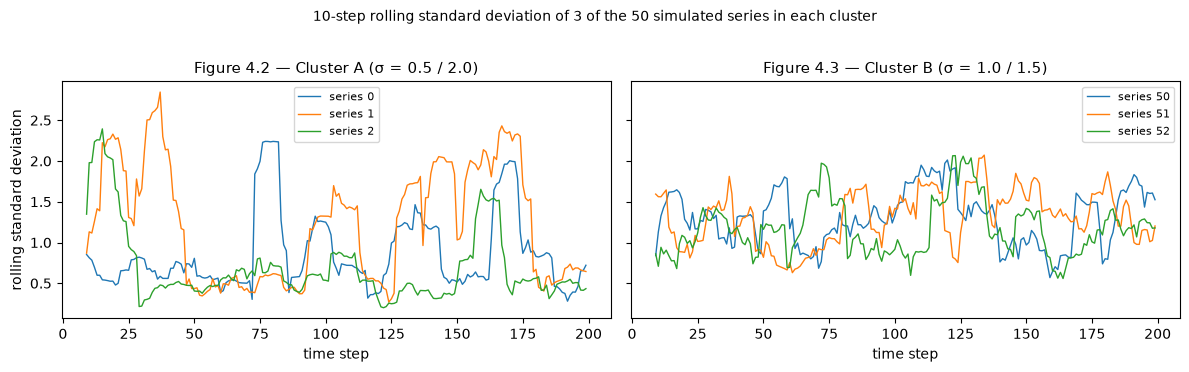

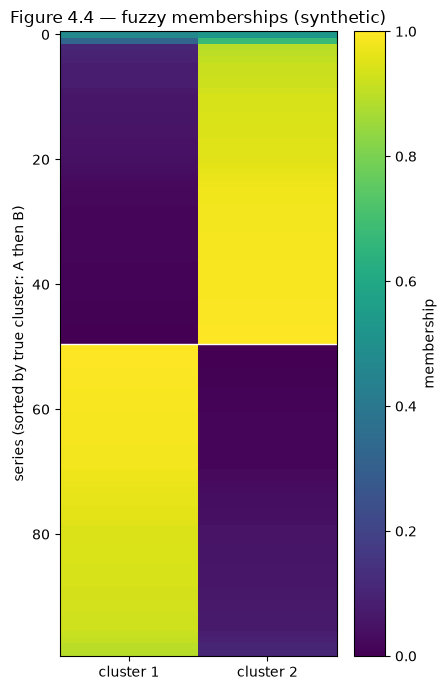

share of series with max membership ≥ 0.8: 0.98


In [11]:
# Figures 4.2 and 4.3: rolling volatility of three sample series per generating cluster (data description)
X, S, y = syn_data[CFG["SEEDS"][0]]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, lab, title in zip(axes, [0, 1], ["Figure 4.2 — Cluster A (σ = 0.5 / 2.0)", "Figure 4.3 — Cluster B (σ = 1.0 / 1.5)"]):
    for i in np.where(y == lab)[0][:3]:
        ax.plot(pd.Series(X[i]).rolling(10).std().values, lw=1, label=f"series {i}")
    ax.set_title(title, fontsize=11); ax.set_xlabel("time step"); ax.legend(fontsize=8)
axes[0].set_ylabel("rolling standard deviation")
fig.suptitle("10-step rolling standard deviation of 3 of the 50 simulated series in each cluster", fontsize=10, y=1.02)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_2_4_3_synthetic_rolling_vol.png", dpi=150); plt.show()

# Figure 4.4: membership heatmap, rows sorted by true cluster
model = syn_models[CFG["SEEDS"][0]]
order = np.lexsort((-model.U_[:, 0], y))
fig, ax = plt.subplots(figsize=(4.5, 7))
im = ax.imshow(model.U_[order], aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(CFG["C_SYN"])); ax.set_xticklabels([f"cluster {j+1}" for j in range(CFG["C_SYN"])])
ax.set_ylabel("series (sorted by true cluster: A then B)"); ax.axhline(CFG["SYN_N_PER"] - 0.5, color="w", lw=1)
ax.set_title("Figure 4.4 — fuzzy memberships (synthetic)"); plt.colorbar(im, ax=ax, label="membership")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_4_membership_heatmap.png", dpi=150); plt.show()
print("share of series with max membership ≥ 0.8:", float((model.U_.max(1) >= 0.8).mean()))

## 8. Experiment 2 — stock indices (Section 4.6.3.2): Table 4.3 (stocks), Figures 4.5–4.7 and 4.10

In [12]:
def prepare_panel(R, val_frac, mode="per_series"):
    X_raw = R.values.T.astype(float)                    # (N, T) decimal log-returns
    train_mask, _ = make_time_masks(X_raw.shape[1], val_frac)
    Z, sd_units = scale_panel(X_raw, train_mask, mode)
    return X_raw, Z, train_mask, sd_units

def high_vol_labels(x_raw, q=CFG["LABEL_QUANTILE"], w=CFG["RV_WINDOW"]):
    rv = realised_vol(x_raw, w); ok = ~np.isnan(rv)
    thr = np.nanquantile(rv, q); return (rv > thr).astype(int), rv, ok

t0 = time.time()
X_raw_s, Z_s, tm_s, sdu_s = prepare_panel(R_STOCKS, CFG["VAL_FRAC"], CFG["STOCK_SCALING"])
print("stock scaling:", CFG["STOCK_SCALING"])
F_s = volatility_features(X_raw_s, tm_s); D_s = kl_distance_matrix(X_raw_s)
stock_rows, stock_models = [], {}
for seed in CFG["SEEDS"]:
    model = vifi_defaults(CFG["C_STOCKS"]).fit(Z_s, F_s, tm_s, seed); stock_models[seed] = model
    r = clustering_metrics(model.U_, D_s); r.update(Method="ViFi-HMM", seed=seed); stock_rows.append(r)
    print(f"seed {seed}: Silhouette {r['Silhouette']:.3f} | best round {model.best_round_} ({time.time()-t0:.0f}s)")
stock_mean, stock_sd, stock_df = mean_sd_table(stock_rows)
print("\nTable 4.3 (stocks) — ViFi-HMM, mean ± sd over seeds")
t43s = fmt_table(stock_mean, stock_sd, ["Silhouette"]); show(t43s)
t43s.to_csv(f"{CFG['OUT_DIR']}/table_4_3_stocks.csv")

stock scaling: per_series
seed 0: Silhouette 0.891 | best round 2 (16s)
seed 1: Silhouette 0.173 | best round 14 (35s)
seed 2: Silhouette 0.173 | best round 14 (50s)
seed 3: Silhouette 0.891 | best round 3 (64s)
seed 4: Silhouette 0.173 | best round 14 (86s)

Table 4.3 (stocks) — ViFi-HMM, mean ± sd over seeds


,Silhouette
Method,
ViFi-HMM,0.460 ± 0.394


In [13]:
best_seed = max(stock_models, key=lambda s: stock_models[s].history_["J_val"].max())
m_s = stock_models[best_seed]
print("Memberships (seed with highest validation J):")
print(pd.DataFrame(m_s.U_, index=STOCK_NAMES, columns=[f"cluster {j+1}" for j in range(CFG['C_STOCKS'])]).round(3))
print("\nState-wise sd (standardised units) and stay probabilities per cluster:")
for j in range(CFG["C_STOCKS"]):
    print(f"  cluster {j+1}: sd calm {m_s.sd_[j,0]:.3f} turbulent {m_s.sd_[j,1]:.3f} | stay {np.round(np.diag(m_s.A_[j]),3).tolist()}")
print("\nPer-sequence KL diagnostic (Eq. 4.8):"); print(pd.DataFrame(m_s.per_sequence_kl(Z_s), index=STOCK_NAMES).round(1))

Memberships (seed with highest validation J):
                   cluster 1  cluster 2
S&P 500                1.000      0.000
NASDAQ                 0.322      0.678
Dow Jones              0.994      0.006
FTSE 100               1.000      0.000
DAX                    0.312      0.688
CAC 40                 0.288      0.712
Nikkei 225             0.322      0.678
Hang Seng              0.328      0.672
S&P/TSX Composite      0.946      0.054
ASX 200                0.989      0.011

State-wise sd (standardised units) and stay probabilities per cluster:
  cluster 1: sd calm 0.577 turbulent 1.713 | stay [0.954, 0.865]
  cluster 2: sd calm 0.556 turbulent 1.542 | stay [0.943, 0.884]

Per-sequence KL diagnostic (Eq. 4.8):
                      0      1
S&P 500            -0.0  119.8
NASDAQ             66.3    4.5
Dow Jones          -0.0  112.7
FTSE 100           -0.0  108.6
DAX                77.8    4.4
CAC 40             88.4    3.4
Nikkei 225         95.0    6.4
Hang Seng          89.1  

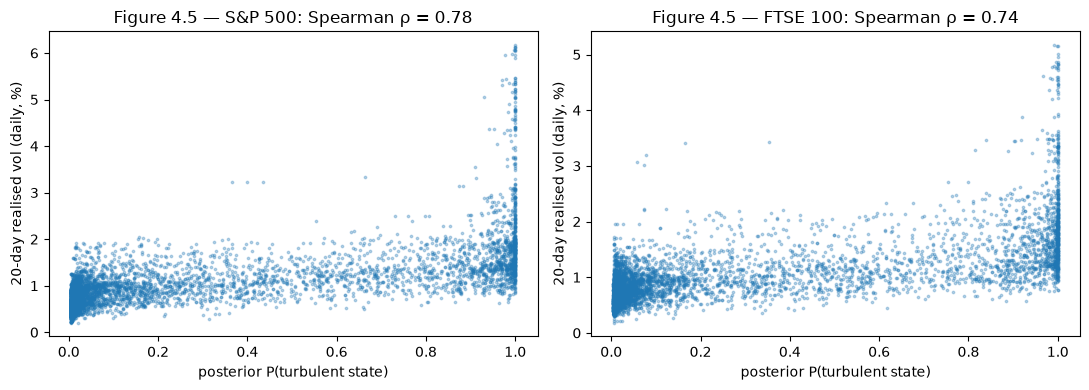

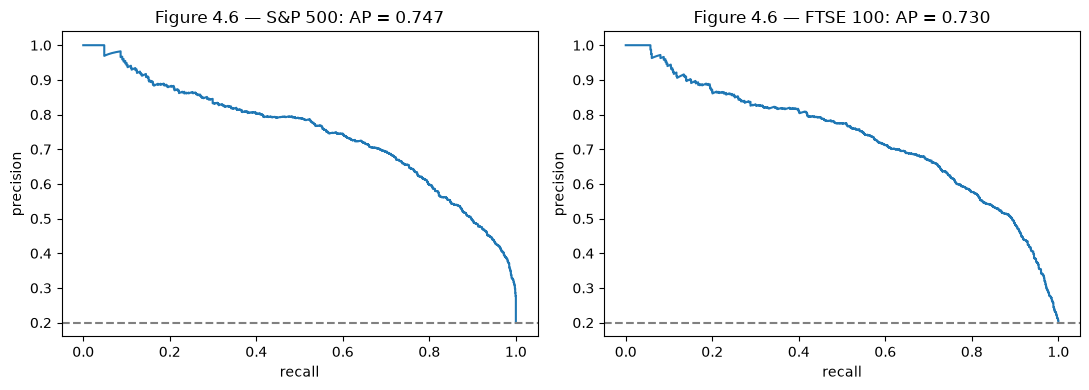

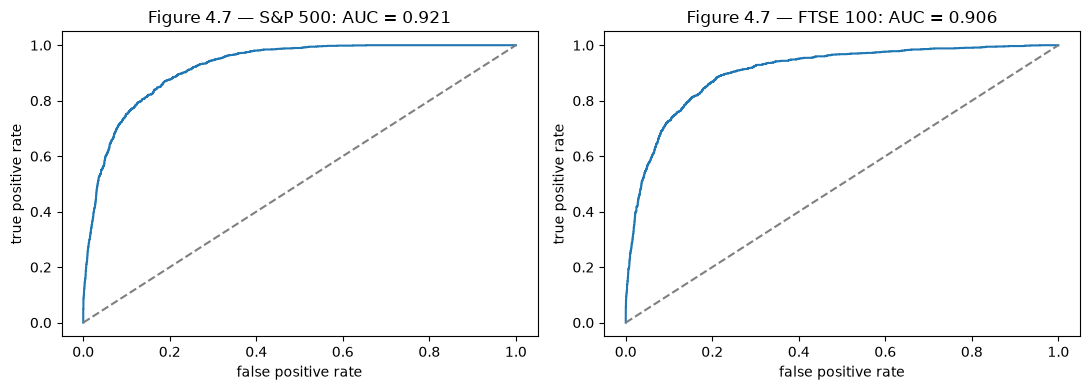

     series     AP    AUC
0   S&P 500  0.747  0.921
1  FTSE 100  0.730  0.906
Labels: day is high-vol when 20-day realised vol > its 80th percentile (in-sample, smoothed posteriors).


In [14]:
# Figures 4.5 (alignment), 4.6 (PR), 4.7 (ROC) for S&P 500 and FTSE 100 — full-sample smoothed posteriors
focus = [n for n in ["S&P 500", "FTSE 100"] if n in STOCK_NAMES] or STOCK_NAMES[:2]
P_high = m_s.consensus_high(Z_s)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, focus):
    i = STOCK_NAMES.index(name); lab, rv, ok = high_vol_labels(X_raw_s[i])
    rho = stats.spearmanr(P_high[i, ok], rv[ok]).correlation
    ax.scatter(P_high[i, ok], rv[ok] / np.sqrt(252), s=3, alpha=0.3)
    ax.set_xlabel("posterior P(turbulent state)"); ax.set_ylabel("20-day realised vol (daily, %)")
    ax.set_title(f"Figure 4.5 — {name}: Spearman ρ = {rho:.2f}")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_5_alignment.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4)); auc_rows = []
for ax, name in zip(axes, focus):
    i = STOCK_NAMES.index(name); lab, rv, ok = high_vol_labels(X_raw_s[i])
    p, r_, _ = precision_recall_curve(lab[ok], P_high[i, ok]); ap = average_precision_score(lab[ok], P_high[i, ok])
    ax.plot(r_, p); ax.axhline(lab[ok].mean(), ls="--", c="grey"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
    ax.set_title(f"Figure 4.6 — {name}: AP = {ap:.3f}"); auc_rows.append(dict(series=name, AP=ap))
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_6_pr.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, (ax, name) in enumerate(zip(axes, focus)):
    i = STOCK_NAMES.index(name); lab, rv, ok = high_vol_labels(X_raw_s[i])
    fpr, tpr, _ = roc_curve(lab[ok], P_high[i, ok]); auc = roc_auc_score(lab[ok], P_high[i, ok])
    ax.plot(fpr, tpr); ax.plot([0, 1], [0, 1], "--", c="grey"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(f"Figure 4.7 — {name}: AUC = {auc:.3f}"); auc_rows[k]["AUC"] = auc
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_7_roc.png", dpi=150); plt.show()
print(pd.DataFrame(auc_rows).round(3))
print(f"Labels: day is high-vol when 20-day realised vol > its {int(CFG['LABEL_QUANTILE']*100)}th percentile (in-sample, smoothed posteriors).")

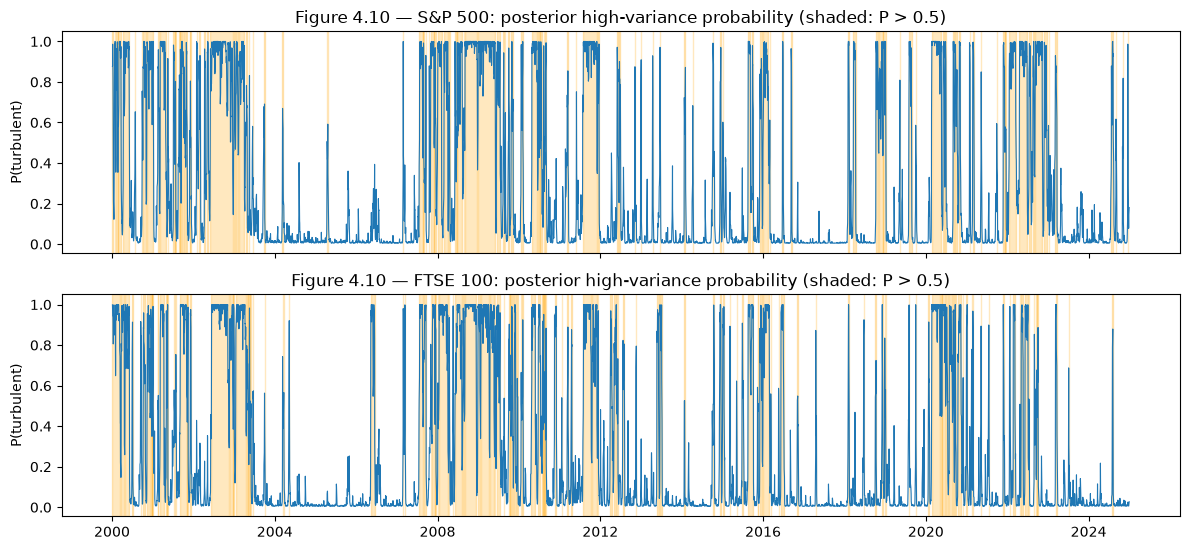

In [15]:
# Figure 4.10: posterior P(turbulent) over time with shaded high-regime periods
fig, axes = plt.subplots(len(focus), 1, figsize=(12, 2.8 * len(focus)), sharex=True)
for ax, name in zip(np.atleast_1d(axes), focus):
    i = STOCK_NAMES.index(name); p = pd.Series(P_high[i], index=R_STOCKS.index)
    ax.plot(p, lw=0.8); ax.fill_between(p.index, 0, 1, where=p > 0.5, color="orange", alpha=0.25, transform=ax.get_xaxis_transform())
    ax.set_ylabel("P(turbulent)"); ax.set_title(f"Figure 4.10 — {name}: posterior high-variance probability (shaded: P > 0.5)")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_10_posterior_timeseries.png", dpi=150); plt.show()

## 9. Temporal hold-out (Figure 4.8): train ≤ 2011, test > 2011

Figure 4.8 / temporal hold-out summary:
     series  loglik_per_obs_train  loglik_per_obs_test  test_AUC  test_AP  \
0   S&P 500                -1.235               -0.968     0.947    0.700   
1  FTSE 100                -1.244               -0.958     0.913    0.663   

   test_spearman  
0          0.710  
1          0.638  


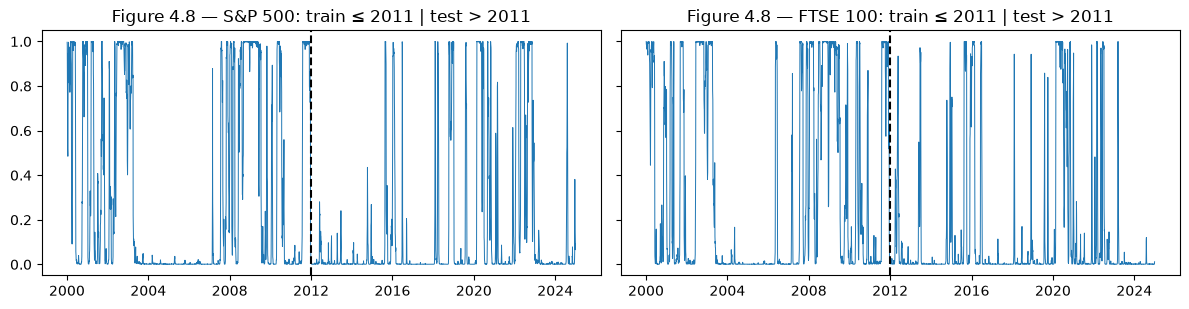

In [16]:
split = pd.Timestamp(CFG["HOLDOUT_SPLIT"])
if not (R_STOCKS.index[0] < split < R_STOCKS.index[-1]):
    split = R_STOCKS.index[len(R_STOCKS) // 2]; print(f"Configured split outside the data range; using the midpoint {split.date()} instead.")
if R_STOCKS.index[0] < split < R_STOCKS.index[-1]:
    tr_mask = np.asarray(R_STOCKS.index <= split)
    Z_h, sdu_h = scale_panel(X_raw_s, tr_mask, CFG["STOCK_SCALING"])
    ho = vifi_defaults(CFG["C_STOCKS"]).fit(Z_h, volatility_features(X_raw_s, tr_mask), tr_mask, CFG["SEEDS"][0])
    G_tr, E_tr = ho.posteriors(Z_h[:, tr_mask]); G_te, E_te = ho.posteriors(Z_h[:, ~tr_mask])
    w = ho.U_ ** ho.m
    ll_tr = (w * E_tr).sum(1) / w.sum(1) / tr_mask.sum(); ll_te = (w * E_te).sum(1) / w.sum(1) / (~tr_mask).sum()
    P_te = ho.consensus_high(Z_h)[:, ~tr_mask]
    rows = []
    for name in focus:
        i = STOCK_NAMES.index(name); lab, rv, ok = high_vol_labels(X_raw_s[i])
        lab_te, ok_te = lab[~tr_mask], ok[~tr_mask]
        rows.append(dict(series=name, loglik_per_obs_train=ll_tr[i], loglik_per_obs_test=ll_te[i],
                         test_AUC=roc_auc_score(lab_te[ok_te], P_te[i, ok_te]), test_AP=average_precision_score(lab_te[ok_te], P_te[i, ok_te]),
                         test_spearman=stats.spearmanr(P_te[i, ok_te], rv[~tr_mask][ok_te]).correlation))
    holdout = pd.DataFrame(rows).round(3); print("Figure 4.8 / temporal hold-out summary:"); print(holdout)
    holdout.to_csv(f"{CFG['OUT_DIR']}/table_holdout_2011.csv", index=False)
    fig, axes = plt.subplots(1, len(focus), figsize=(12, 3.2), sharey=True)
    for ax, name in zip(np.atleast_1d(axes), focus):
        i = STOCK_NAMES.index(name); p = pd.Series(ho.consensus_high(Z_h)[i], index=R_STOCKS.index)
        ax.plot(p, lw=0.7); ax.axvline(split, color="k", ls="--"); ax.set_title(f"Figure 4.8 — {name}: train ≤ {split.year} | test > {split.year}")
    plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_8_holdout.png", dpi=150); plt.show()
else:
    print("Hold-out skipped: the data range does not span", split.date())

## 10. Experiment 3 — currency pairs (Section 4.6.4): Table 4.3 (FX), Figure 4.9

FX scaling: common
seed 0: Silhouette 0.346 (9s)
seed 1: Silhouette 0.412 (20s)
seed 2: Silhouette 0.346 (31s)
seed 3: Silhouette 0.346 (40s)
seed 4: Silhouette 0.353 (52s)

Table 4.3 (FX) — ViFi-HMM, mean ± sd over seeds


,Silhouette
Method,
ViFi-HMM,0.361 ± 0.029


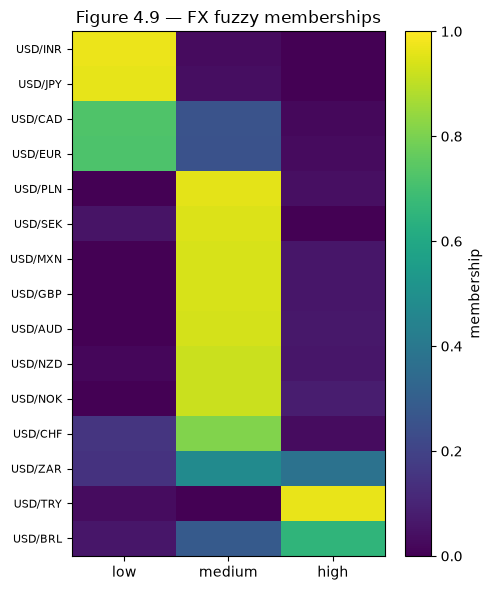

           low  medium   high
USD/EUR  0.719   0.251  0.030
USD/GBP  0.000   0.939  0.061
USD/JPY  0.963   0.037  0.000
USD/CHF  0.155   0.812  0.033
USD/CAD  0.726   0.254  0.020
USD/AUD  0.000   0.936  0.064
USD/NZD  0.018   0.921  0.061
USD/SEK  0.054   0.946  0.000
USD/NOK  0.000   0.920  0.080
USD/MXN  0.000   0.941  0.059
USD/ZAR  0.147   0.477  0.376
USD/BRL  0.061   0.283  0.656
USD/TRY  0.031   0.000  0.969
USD/INR  0.973   0.027  0.000
USD/PLN  0.000   0.959  0.041

Cluster volatility levels (valid for FX_SCALING='common'):
        calm sd (daily %)  turbulent sd (daily %)  stay calm  stay turbulent
low                 0.293                   0.738      0.924           0.859
medium              0.421                   1.013      0.924           0.875
high                0.639                   2.049      0.954           0.871


In [17]:
t0 = time.time()
X_raw_f, Z_f, tm_f, sdu_f = prepare_panel(R_FX, CFG["VAL_FRAC"], CFG["FX_SCALING"])
print("FX scaling:", CFG["FX_SCALING"])
F_f = volatility_features(X_raw_f, tm_f); D_f = kl_distance_matrix(X_raw_f)
fx_rows, fx_models = [], {}
for seed in CFG["SEEDS"]:
    model = vifi_defaults(CFG["C_FX"]).fit(Z_f, F_f, tm_f, seed); fx_models[seed] = model
    r = clustering_metrics(model.U_, D_f); r.update(Method="ViFi-HMM", seed=seed); fx_rows.append(r)
    print(f"seed {seed}: Silhouette {r['Silhouette']:.3f} ({time.time()-t0:.0f}s)")
fx_mean, fx_sd, fx_df = mean_sd_table(fx_rows)
print("\nTable 4.3 (FX) — ViFi-HMM, mean ± sd over seeds"); t43f = fmt_table(fx_mean, fx_sd, ["Silhouette"]); show(t43f)
t43f.to_csv(f"{CFG['OUT_DIR']}/table_4_3_fx.csv")

m_f = fx_models[max(fx_models, key=lambda s: fx_models[s].history_["J_val"].max())]
# order clusters by turbulent-state sd for the low / medium / high reading
ordc = np.argsort(m_f.sd_[:, 1]); Uf = m_f.U_[:, ordc]
fig, ax = plt.subplots(figsize=(5, 6))
row_order = np.lexsort((-Uf.max(1), Uf.argmax(1)))
im = ax.imshow(Uf[row_order], aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(FX_NAMES))); ax.set_yticklabels(np.array(FX_NAMES)[row_order], fontsize=8)
ax.set_xticks(range(CFG["C_FX"])); ax.set_xticklabels(["low", "medium", "high"][:CFG["C_FX"]])
ax.set_title("Figure 4.9 — FX fuzzy memberships"); plt.colorbar(im, ax=ax, label="membership")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_4_9_fx_heatmap.png", dpi=150); plt.show()
print(pd.DataFrame(Uf, index=FX_NAMES, columns=["low", "medium", "high"][:CFG["C_FX"]]).round(3))
lv = pd.DataFrame({"calm sd (daily %)": m_f.sd_[ordc, 0] * sdu_f[0, 0] * 100, "turbulent sd (daily %)": m_f.sd_[ordc, 1] * sdu_f[0, 0] * 100,
                   "stay calm": [m_f.A_[j][0, 0] for j in ordc], "stay turbulent": [m_f.A_[j][1, 1] for j in ordc]},
                  index=["low", "medium", "high"][:CFG["C_FX"]])
print("\nCluster volatility levels (valid for FX_SCALING='common'):"); print(lv.round(3))

## 11. Ablation (Section 4.6.6, Table 4.5): full model against hard assignment (m = 1)

In [18]:
t0 = time.time(); abl_rows = []
variants = {"Full ViFi-HMM": {}, "m = 1 (hard assignment)": dict(m=1.0, hard=True)}
for seed in CFG["SEEDS"]:
    for vname, over in variants.items():
        if vname == "Full ViFi-HMM": model = stock_models[seed]
        else: model = vifi_defaults(CFG["C_STOCKS"], **over).fit(Z_s, F_s, tm_s, seed)
        r = clustering_metrics(model.U_, D_s); r.update(Variant=vname, seed=seed); abl_rows.append(r)
    print(f"seed {seed} done ({time.time()-t0:.0f}s)")
abl_mean, abl_sd, abl_df = mean_sd_table(abl_rows, "Variant")
print("\nTable 4.5 — ablation on stock indices"); t45 = fmt_table(abl_mean, abl_sd, ["Silhouette"]); show(t45)
t45.to_csv(f"{CFG['OUT_DIR']}/table_4_5_ablation.csv")

seed 0 done (12s)
seed 1 done (25s)
seed 2 done (37s)
seed 3 done (51s)
seed 4 done (65s)

Table 4.5 — ablation on stock indices


,Silhouette
Variant,
Full ViFi-HMM,0.460 ± 0.394
m = 1 (hard assignment),0.149 ± 0.062


## 12. Downstream risk (Table 4.4): VaR breach rate

* **Model and period.** The hold-out model of Section 9 (trained on data up to 2011) is applied to **2012–2024**,
  which is split into **five equal sub-periods**; the table reports the mean ± sd across them.
* **One-step-ahead volatility.** For day *t*, each index's predicted volatility uses information up to *t−1* only:
  the causal (filtered) state distribution is propagated one step through the transition matrix, and the state
  standard deviations (in return units) are averaged under it and under the index's fuzzy memberships.
  Baseline: RiskMetrics EWMA (λ = 0.94).
* **VaR breach rate.** Share of days whose loss exceeds the one-day 95 % Gaussian VaR, 1.645 × predicted volatility.
  The nominal rate is 5 %.

In [19]:
def one_step_vol(model, Z, sd_units):
    """Predicted daily volatility (N,T, return units), using information to t-1."""
    P_f = filtered_posteriors(Z, model.pi_, model.A_, model.mu_, model.sd_)                 # (N,C,T,K)
    pred = np.einsum("nctk,ckl->nctl", P_f, model.A_)                                        # state distribution for t+1
    w = model.U_ ** model.m; w = w / w.sum(1, keepdims=True)
    sig_state = model.sd_[None] * sd_units.reshape(-1)[:, None, None]                         # (N,C,K) return units
    vol = np.einsum("nc,nctk,nck->nt", w, pred, sig_state)
    first = np.sqrt((sig_state ** 2).mean((1, 2)))
    return np.c_[first, vol[:, :-1]]                                                          # shift: day t uses t-1

def ewma_vol(X_raw, train_mask, lam=0.94):
    N, T = X_raw.shape; v = np.empty((N, T)); v[:, 0] = X_raw[:, train_mask].var(1)
    for t in range(1, T): v[:, t] = lam * v[:, t - 1] + (1 - lam) * X_raw[:, t - 1] ** 2
    return np.sqrt(v)

def var_breach_oos(model, Z, X_raw, sd_units, train_mask, n_periods=5):
    test_idx = np.where(~train_mask)[0]; out = {}
    for name, vol in [("EWMA baseline", ewma_vol(X_raw, train_mask)), ("ViFi-HMM", one_step_vol(model, Z, sd_units))]:
        vb = [100 * float((X_raw[:, blk] < -1.645 * np.maximum(vol[:, blk], 1e-6)).mean()) for blk in np.array_split(test_idx, n_periods)]
        out[name] = {"VaR breach rate (%)": f"{np.mean(vb):.3f} ± {np.std(vb):.3f}"}
    return pd.DataFrame(out)

if "ho" in dir():
    table_4_4 = var_breach_oos(ho, Z_h, X_raw_s, sdu_h, tr_mask)
    print(f"Table 4.4 — out-of-sample VaR breach rate, {len(STOCK_NAMES)} indices, test period after {split.date()}, mean ± sd over 5 sub-periods")
    show(table_4_4); table_4_4.to_csv(f"{CFG['OUT_DIR']}/table_4_4_downstream.csv")
else:
    print("Table 4.4 skipped: the hold-out model is unavailable for this data range.")

Table 4.4 — out-of-sample VaR breach rate, 10 indices, test period after 2011-12-31, mean ± sd over 5 sub-periods


,EWMA baseline,ViFi-HMM
VaR breach rate (%),5.923 ± 0.244,4.361 ± 1.006


## 13. Run summary

In [20]:
summary = dict(real_data=DATA["real"], quick_mode=QUICK, seeds=CFG["SEEDS"], restarts=CFG["RESTARTS"],
               standardise=CFG["STANDARDISE"], stock_series=STOCK_NAMES, fx_series=FX_NAMES,
               n_days_stocks=int(R_STOCKS.shape[0]), n_days_fx=int(R_FX.shape[0]),
               stock_calendar=CFG["STOCK_CALENDAR"], bad_ticks_removed=n_removed,
               outputs=sorted(os.listdir(CFG["OUT_DIR"])))
json.dump(summary, open(f"{CFG['OUT_DIR']}/run_summary.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
if not DATA["real"]:
    print("\nREMINDER: this run used simulated stand-in data. Install yfinance (pip install yfinance) and re-run for the thesis results.")

{
  "real_data": true,
  "quick_mode": false,
  "seeds": [
    0,
    1,
    2,
    3,
    4
  ],
  "restarts": 5,
  "standardise": true,
  "stock_series": [
    "S&P 500",
    "NASDAQ",
    "Dow Jones",
    "FTSE 100",
    "DAX",
    "CAC 40",
    "Nikkei 225",
    "Hang Seng",
    "S&P/TSX Composite",
    "ASX 200"
  ],
  "fx_series": [
    "USD/EUR",
    "USD/GBP",
    "USD/JPY",
    "USD/CHF",
    "USD/CAD",
    "USD/AUD",
    "USD/NZD",
    "USD/SEK",
    "USD/NOK",
    "USD/MXN",
    "USD/ZAR",
    "USD/BRL",
    "USD/TRY",
    "USD/INR",
    "USD/PLN"
  ],
  "n_days_stocks": 6502,
  "n_days_fx": 2606,
  "stock_calendar": "union_ffill",
  "bad_ticks_removed": 5,
  "outputs": [
    "data_cleaning_report.csv",
    "data_quality_max_moves.csv",
    "data_zero_return_days.csv",
    "fig_4_10_posterior_timeseries.png",
    "fig_4_2_4_3_synthetic_rolling_vol.png",
    "fig_4_4_membership_heatmap.png",
    "fig_4_5_alignment.png",
    "fig_4_6_pr.png",
    "fig_4_7_roc.png",
    "fig_4_

## 14. Running this for the thesis

1. `pip install yfinance`.
2. Set `QUICK = False` (or leave the `CH4_QUICK` environment variable unset).
3. Run all cells. With five seeds and five restarts the full run takes roughly one to two hours on a laptop.
4. Everything in `outputs_ch4/` (tables as CSV, figures as PNG, `run_summary.json`) is the record of the run. Keep the
   executed notebook with the thesis as the provenance record, as for Chapters 5 and 6.